In [45]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange, repeat
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.autograd import grad, Variable

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.my_uoro import UORO

%load_ext autoreload
%autoreload 2
device = 'cuda:0'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=1, l=4, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [84]:
loss_all=[]
l = []
loss_acc=0
input_size=3
hidden_size=100
output_size=3
old_s = torch.zeros(size=[1, 1, hidden_size], requires_grad=True, device=device)
criterion=torch.nn.CrossEntropyLoss()
model=SimpleRNN(3,hidden_size,3).to(device)
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)

In [91]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss=criterion(y[0], y_t)
        uoro_grad.step(model, x_t, new_s, old_s, loss)
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

382.75474590761587
390.92423417506507
376.2688050166471
386.0996873836266
373.1249709430849
357.6871320975479
371.3962703884463
385.4753993633203
382.81323995412095
376.40060595731484
369.600663247169
390.58705896102765
371.6907503348193
380.440886104072
368.6112631292199
353.83409789262805
366.0971193416044
381.1423709137598
377.9225684541161
371.86685828870395
365.29052221786696
386.81690536328824
366.99064628902124
378.8246159902192
364.39481659507146
348.0623337397119
362.8704424329335
377.8366305125528
373.0413849375909
369.9771350316587
361.5425963579328
382.088801950842
361.41282879782375
371.25687717692927
359.5750870196498
342.90181258600205
357.4350798415835
373.04948097793385
367.6350407637656
363.5746952588088
357.3565670613316
377.8167916380771
356.7243659790256
366.75926857593004
355.7409711232758
338.86496777494904
353.2529675537953
367.25595957401674
362.6964820002613
358.458868877904
352.51694082212634
372.28849354847625
351.7705387643364
361.27349265513476
350.8505748

KeyboardInterrupt: 

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss+=criterion(y.squeeze(0), y_t)
        # uoro_grad.step(model, x_t, new_s, old_s, loss)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [97]:
from memoryPerceiver.memory_perceiver.main.configuration import cf
loss_all = []
loss_acc=0
criterion=torch.nn.CrossEntropyLoss()
cf.body_outputs['critic']=3 # agent.py -> values = rearrange(output['critic'], 'b () d -> b d')
cf.shared=True 
cf.dim_observations=3
cf.num_envs=1
cf.depth=1
cf.query_dim=12
cf.nb_latents=4
cf.nb_latents_mem=4
cf.latent_dim_head=4
model=create_agent(cf, device)
old_s = create_memories(model.actor, cf.num_envs, device=device)
mem_dim = old_s.shape
old_s = rearrange(old_s, 'b d l h -> (b d l h)')
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
dummy0=torch.zeros(cf.num_envs, 1, cf.dim_actions, device=device)
states = {}

In [95]:
print(uoro_grad.theta_tilda.shape)

torch.Size([8909])


In [98]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        uoro_grad.step(model, states, new_s, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

1.348317265510559
1048.1334879994392


In [56]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)

        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        loss+=criterion(y, y_t)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

21.6447950899601
68.53889608383179
71.04755687713623
69.98336124420166
68.75531148910522
68.08237981796265
66.87770771980286
69.14485740661621
70.65732312202454
69.35808730125427
68.86849236488342
69.9894528388977
68.21034646034241
67.16703963279724
66.32435822486877
65.5203595161438
70.61768412590027
69.11923122406006
69.19228339195251
69.57874846458435
67.9222674369812
71.43164587020874
69.42055177688599
67.42951083183289
67.89390563964844
68.8931336402893
70.66663599014282
68.89344477653503
68.14134097099304
65.8185064792633
68.07726573944092
67.6535313129425
67.07759952545166
69.1725025177002
67.85021734237671
67.90986657142639
69.60684776306152
67.70091891288757
71.07934308052063
67.04156398773193
66.1854944229126
67.81860542297363
69.72536158561707
69.17391896247864
70.22668194770813
67.5654628276825
67.7313756942749
68.08818745613098
66.14429068565369
67.36404538154602
68.10076999664307
69.81894826889038
68.42997932434082
69.26548099517822
67.72549939155579
65.47410988807678
69.

KeyboardInterrupt: 

In [ ]:
for param_group in optimizer.param_groups:
    param_group['lr'] = 1e-5

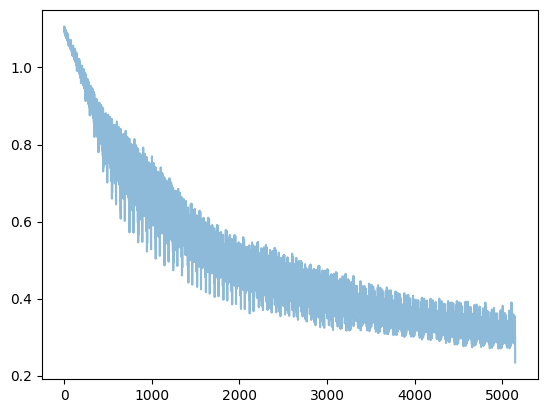

In [92]:
# < 0.68 and close to 0.25 RNN
# plt.plot(loss_all)
h=100
plt.plot([sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.5)
# plt.scatter(x=list(range(0,len(loss_all),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.1)
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)